# Analysis

Python is the default kernel. An R kernel is fine if that is the language you can explain. `CHECKLIST.md` is the list that counts. The ticks on the lab page do not.

The held-out score, in the units of the decision, is computed in this notebook. The reason slide in `presentation.qmd` has to agree with it. The risk slide is the risk of the action, not this score.


## Setup

Import what you use and set the random seed. Pin those packages in `requirements.txt` and the interpreter in `.python-version`, or use `renv.lock` for R. When a result depends on the draw, record the seed in `decisions.md`. Before fitting, check each file in `data/` against the SHA-256 in `data/README.md`.


In [1]:
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

SEED = 2
rng = np.random.default_rng(SEED)

expected_sha256 = {
    "data/clip-log.csv": "04f9a869dd29f868da53fc15173f7762b03343dfbd1cb16932f6e9a1464b4827",
}
for path, expected in expected_sha256.items():
    got = hashlib.sha256(Path(path).read_bytes()).hexdigest()
    assert got == expected, f"{path} does not match the hash in data/README.md"
    print("checksum ok:", path)


checksum ok: data/clip-log.csv


# Question

**Question.** Can a clip's image clarity predict human review time more accurately than using one average review time for every clip?

**Quantity.** Reviewer time in **seconds per unseen one-minute clip**, for clips like the 20 parking-lot recordings collected on **16 November 2026** and reviewed on **17–18 November 2026**.

**Decision.** A small annotation / imagery-review business uses the prediction to schedule reviewer time and estimate labor cost for similar clips. Underestimating work is treated as the costlier mistake in Part 3 because it can create rush or overtime pressure.

![Layer diagram](fig/layers.png)


## Data

The dataset contains **20 one-minute clips** of parked civilian passenger cars recorded by the team in outdoor retail parking lots during one evening. One clip is the unit of observation. For each clip, one reviewer examined 12 sampled still frames and recorded the total review time in seconds. Clarity has three labels: `clear`, `moderately unclear`, and `very unclear`.

The decision needs reviewer time for a future unseen clip. The measurement is narrower: one reviewer, one evening, dusk/night scenes, and review of pre-extracted stills rather than the full file-handling workflow. Those differences create **bias** if future jobs systematically take longer or involve different reviewers/scenes, while clip-to-clip timing variation is **noise**.

The clarity labels are a major limitation: they were assigned after timing rather than blindly before timing, so the clarity–time relationship may be overstated. The notebook therefore treats the result as evidence for this small sample, not as a general production model.

The released `data/clip-log.csv` is checked against the SHA-256 recorded in the project documentation before fitting. The raw-data plot and summary table below come before the model.


rows: 20  missing values per column:
Clip ID                       0
Session ID                    0
Source file                   0
Recorded at                   0
Clarity                       0
review_time_sec_measured      0
review_time_sec_simulated     0
Interruption sec              0
Notes                        20
Review date                   0
Reviewer                      0
dtype: int64
duplicated Clip ID: False
Interruption sec, unique values: [0]
review_time_sec_measured range: 51 - 93 s

Review time (seconds) by clarity label, all 20 clips:
                     n  mean   sd  min  max
Clarity                                    
clear                6  54.8  4.8   51   61
moderately unclear  12  76.2  7.7   60   89
very unclear         2  86.0  9.9   79   93


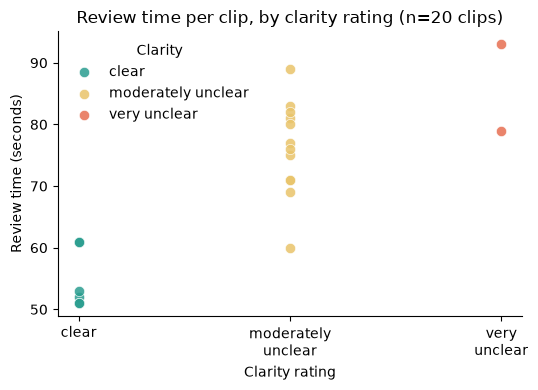

,n,mean,sd,min,max
Clarity,,,,,
clear,6,54.833333,4.833908,51,61
moderately unclear,12,76.166667,7.696910,60,89
very unclear,2,86.000000,9.899495,79,93


In [2]:
df = pd.read_csv("data/clip-log.csv")

# Data-quality pass (Part 2, step 1): missing values and timing mistakes.
print("rows:", len(df), " missing values per column:")
print(df.isna().sum())
print("duplicated Clip ID:", df["Clip ID"].duplicated().any())
print("Interruption sec, unique values:", df["Interruption sec"].unique())
print("review_time_sec_measured range:", df.review_time_sec_measured.min(), "-", df.review_time_sec_measured.max(), "s")
# No missing measurements, no duplicate clips, no interruptions logged, times all in a plausible
# 51-93 s range. The only "not collected" field is car counts (see data/README.md); the
# hypothesis in PROPOSAL.md does not need them, so that gap does not block this analysis.

order = {"clear": 1, "moderately unclear": 2, "very unclear": 3}
df["clarity_score"] = df["Clarity"].map(order)

summary = (
    df.groupby("Clarity")["review_time_sec_measured"]
    .agg(n="count", mean="mean", sd="std", min="min", max="max")
    .reindex(["clear", "moderately unclear", "very unclear"])
)
print()
print("Review time (seconds) by clarity label, all 20 clips:")
print(summary.round(1))

fig, ax = plt.subplots(figsize=(5.5, 4))
colors = {"clear": "#2a9d8f", "moderately unclear": "#e9c46a", "very unclear": "#e76f51"}
for label in ["clear", "moderately unclear", "very unclear"]:
    sub = df[df.Clarity == label]
    ax.scatter(sub.clarity_score, sub.review_time_sec_measured, color=colors[label],
               label=label, s=55, alpha=0.85, edgecolor="white", linewidth=0.5, zorder=3)
ax.set_xticks([1, 2, 3])
ax.set_xticklabels(["clear", "moderately\nunclear", "very\nunclear"])
ax.set_xlabel("Clarity rating")
ax.set_ylabel("Review time (seconds)")
ax.set_title("Review time per clip, by clarity rating (n=20 clips)")
ax.legend(title="Clarity", frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("fig/review_time_by_clarity.png", dpi=150)
plt.show()
summary


## Split

The held-out clips are `C03`, `C07`, `C16`, `C17`, and `C20`; the other 15 clips are training data. The split is fixed and recorded in `decisions.md`. Simultaneous two-phone pairs are kept together; `C16/C17` is the pair placed in test. The held-out set contains all three clarity levels so the tiny test set is at least able to check each category.


In [3]:
# Held-out test set: 5 clips, train on the other 15 (PROPOSAL.md: ~15 train / 5 test).
# Session S01 (C01-C02) and S02 (C03-C20) are too unbalanced (2 vs 18) to split on directly
# (decisions.md, "Sessions by a 5-minute gap"). That same entry allows a finer split in Part 2,
# as long as each simultaneous two-phone pair stays on one side:
# (C10,C11), (C12,C13), (C14,C15), (C16,C17), (C18,C19).
#
# Chosen test set, fixed by hand rather than drawn at random: {C03, C07, C16, C17, C20}.
# C16/C17 is the one paired unit sent to test, kept whole. The other four pairs, including
# the only pair that contains a "very unclear" clip (C14/C15), stay in train so that category
# is not reduced to zero training examples. The three singles (C03, C07, C20) were picked so the
# test set still has all three clarity labels represented (2 clear, 2 moderately unclear,
# 1 very unclear), rather than leaving that to chance with only 20 clips to draw from.
test_ids = ["C03", "C07", "C16", "C17", "C20"]
df["split"] = np.where(df["Clip ID"].isin(test_ids), "test", "train")

train = df[df.split == "train"].copy()
test = df[df.split == "test"].copy()

print("train:", len(train), "clips  |  test:", len(test), "clips")
print()
print("train, by clarity:\n", train.Clarity.value_counts())
print()
print("test, by clarity:\n", test.Clarity.value_counts())


train: 15 clips  |  test: 5 clips

train, by clarity:
 Clarity
moderately unclear    10
clear                  4
very unclear           1
Name: count, dtype: int64

test, by clarity:
 Clarity
moderately unclear    2
clear                 2
very unclear          1
Name: count, dtype: int64


## Baseline

The baseline predicts the **training-set mean review time for every clip**. This is the simplest staffing rule: use one average time regardless of clarity. It is scored on the same five held-out clips as the model using mean absolute error (MAE) in seconds.


In [4]:
# Baseline: predict the training mean review time for every clip, regardless of clarity.
baseline_pred = train.review_time_sec_measured.mean()
print(f"Baseline prediction (train mean): {baseline_pred:.2f} s, for every clip")

test_pred_baseline = np.full(len(test), baseline_pred)
mae_baseline = np.mean(np.abs(test.review_time_sec_measured.values - test_pred_baseline))
print(f"Baseline MAE on the 5 held-out clips: {mae_baseline:.2f} s")


Baseline prediction (train mean): 70.40 s, for every clip
Baseline MAE on the 5 held-out clips: 12.92 s


## Model

We fit the simple linear model

\[
y_i = b_0 + b_1 x_i + \varepsilon_i,
\qquad \varepsilon_i \sim N(0,\sigma^2),
\]

where `y_i` is measured review time in seconds and `x_i` is the ordinal clarity score (`clear=1`, `moderately unclear=2`, `very unclear=3`).

- **`b0` (intercept):** the line's baseline level; mathematically it is the predicted time at clarity score 0, which is outside the observed labels and is not interpreted as a real clip type.
- **`b1` (slope):** expected change in review seconds for moving one clarity level toward a less clear image.
- **`sigma` (residual SD):** remaining clip-to-clip timing variation not explained by clarity.

Main assumptions: the three clarity levels can be represented by equally spaced scores; the mean relationship is approximately linear; residual variation is roughly stable and approximately normal; and train/test clips are representative of future similar clips. **The assumption trusted least is that clarity is independent evidence**, because the labels were assigned after timing and after preliminary AI-assisted ratings were seen.


In [5]:
# Model: review_time_sec_measured = b0 + b1 * clarity_score + error
#   clarity_score: clear=1, moderately unclear=2, very unclear=3 (ordinal, one parameter
#   instead of two dummy variables, which matters with only 15 training clips).
#   b0: predicted review time at clarity_score=0 (an extrapolation; has no standalone meaning).
#   b1: predicted extra seconds per one-step increase in clarity difficulty.
#   error: assumed independent of clarity_score, roughly constant spread (checked below).
slope, intercept, r_value, p_value, se_slope = stats.linregress(
    train.clarity_score, train.review_time_sec_measured
)
print(f"fitted: review_time = {intercept:.2f} + {slope:.2f} * clarity_score")
print(f"slope standard error: {se_slope:.2f} s per clarity step  (p = {p_value:.4f}, r = {r_value:.2f})")

train_pred_model = intercept + slope * train.clarity_score
resid_train = train.review_time_sec_measured - train_pred_model
resid_sd = resid_train.std(ddof=2)  # 2 fitted parameters
print(f"residual standard deviation on training data: {resid_sd:.2f} s")

test_pred_model = intercept + slope * test.clarity_score
mae_model = np.mean(np.abs(test.review_time_sec_measured.values - test_pred_model.values))
print(f"Model MAE on the 5 held-out clips: {mae_model:.2f} s")

# Uncertainty on the two held-out MAEs: bootstrap resample the 5 test clips (with replacement),
# 20,000 times, since n=5 is too small for a normal-theory interval to mean much.
errs_baseline = np.abs(test.review_time_sec_measured.values - test_pred_baseline)
errs_model = np.abs(test.review_time_sec_measured.values - test_pred_model.values)
n_test = len(test)
boot_idx = rng.integers(0, n_test, size=(20_000, n_test))
boot_baseline = errs_baseline[boot_idx].mean(axis=1)
boot_model = errs_model[boot_idx].mean(axis=1)
boot_diff = boot_model - boot_baseline

ci_baseline = np.percentile(boot_baseline, [5, 95])
ci_model = np.percentile(boot_model, [5, 95])
ci_diff = np.percentile(boot_diff, [5, 95])

print()
print(f"MAE baseline: {mae_baseline:.2f} s   90% bootstrap interval {ci_baseline.round(2)}")
print(f"MAE model:    {mae_model:.2f} s   90% bootstrap interval {ci_model.round(2)}")
print(f"MAE(model) - MAE(baseline): {mae_model - mae_baseline:.2f} s   90% interval {ci_diff.round(2)}")
print("(a fully negative interval here means the model beat the baseline on every resample")
print(" of these same 5 clips -- it does not mean the model would do this well on new footage)")

results_table = test[["Clip ID", "Clarity", "review_time_sec_measured"]].copy()
results_table["pred_baseline"] = test_pred_baseline.round(1)
results_table["pred_model"] = test_pred_model.round(1)
results_table["abs_err_baseline"] = errs_baseline.round(1)
results_table["abs_err_model"] = errs_model.round(1)
results_table


fitted: review_time = 40.45 + 16.64 * clarity_score
slope standard error: 3.86 s per clarity step  (p = 0.0009, r = 0.77)
residual standard deviation on training data: 8.10 s
Model MAE on the 5 held-out clips: 4.93 s

MAE baseline: 12.92 s   90% bootstrap interval [ 7.16 18.6 ]
MAE model:    4.93 s   90% bootstrap interval [3.18 6.89]
MAE(model) - MAE(baseline): -7.99 s   90% interval [-13.97  -2.48]
(a fully negative interval here means the model beat the baseline on every resample
 of these same 5 clips -- it does not mean the model would do this well on new footage)


,Clip ID,Clarity,review_time_sec_measured,pred_baseline,pred_model,abs_err_baseline,abs_err_model
2,C03,moderately unclear,83,70.4,73.7,12.6,9.3
6,C07,very unclear,93,70.4,90.4,22.6,2.6
15,C16,moderately unclear,71,70.4,73.7,0.6,2.7
16,C17,clear,51,70.4,57.1,19.4,6.1
19,C20,clear,61,70.4,57.1,9.4,3.9


## Simulation check

To check the fitting procedure, we simulate review times from the fitted linear model using the observed training clarity scores, then refit the model 2,000 times. If the procedure is working, the average recovered intercept and slope should be close to the parameters used to generate the simulations.


In [6]:
# Simulate data from the fitted model (same training clarity scores, known b0, b1, resid_sd),
# refit many times, and check that the fitting procedure recovers the parameters it was given.
n_sims = 2000
x_train = train.clarity_score.values
sim_slopes = np.empty(n_sims)
sim_intercepts = np.empty(n_sims)

for i in range(n_sims):
    y_sim = intercept + slope * x_train + rng.normal(0, resid_sd, size=len(x_train))
    s, b, _, _, _ = stats.linregress(x_train, y_sim)
    sim_slopes[i] = s
    sim_intercepts[i] = b

print(f"true slope {slope:.2f}      recovered mean {sim_slopes.mean():.2f}, sd {sim_slopes.std():.2f}")
print(f"true intercept {intercept:.2f}  recovered mean {sim_intercepts.mean():.2f}, sd {sim_intercepts.std():.2f}")
print("The simulated-and-refit slope and intercept land right on the values used to simulate")
print("them, so the fitting code is not the source of error here -- the 15-clip training set is.")


true slope 16.64      recovered mean 16.68, sd 3.81
true intercept 40.45  recovered mean 40.33, sd 7.16
The simulated-and-refit slope and intercept land right on the values used to simulate
them, so the fitting code is not the source of error here -- the 15-clip training set is.


## Residuals and uncertainty

Residual plots below check whether errors look like random noise or show systematic structure. We also carry uncertainty into Part 3 with approximate **90% prediction intervals for new clips**, which include both residual variation and uncertainty in the fitted line. Because there are only five held-out clips, interval coverage is only a weak calibration check.

Forecast uncertainty is smallest around clarity scores well represented in the training data and grows when predicting at sparsely represented levels, especially `very unclear`, which has only one training clip.


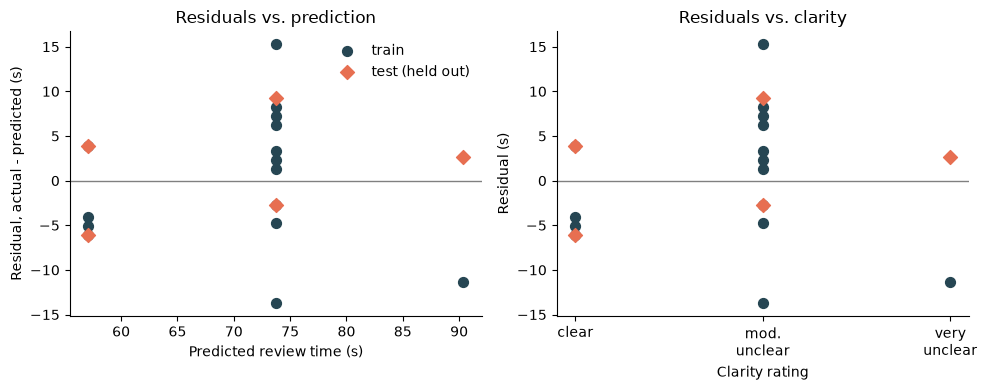

Training residuals look like noise scattered around 0 at every clarity level, with no
obvious curve or fan shape -- consistent with the straight-line, constant-spread model.
The spread is similar across the three clarity groups (no strong fan pattern), so a single
residual standard deviation for all three groups is a reasonable simplification here,
though with only 1 training clip in the 'very unclear' group that check is weak for that
group specifically. The held-out (diamond) points sit inside the training scatter, not
systematically above or below it.


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].axhline(0, color="grey", linewidth=1, zorder=1)
axes[0].scatter(train_pred_model, resid_train, color="#264653", s=50, zorder=3, label="train")
axes[0].scatter(test_pred_model, test.review_time_sec_measured.values - test_pred_model.values,
                color="#e76f51", s=50, zorder=3, marker="D", label="test (held out)")
axes[0].set_xlabel("Predicted review time (s)")
axes[0].set_ylabel("Residual, actual - predicted (s)")
axes[0].set_title("Residuals vs. prediction")
axes[0].legend(frameon=False)
axes[0].spines[["top", "right"]].set_visible(False)

axes[1].axhline(0, color="grey", linewidth=1, zorder=1)
axes[1].scatter(train.clarity_score, resid_train, color="#264653", s=50, zorder=3)
axes[1].scatter(test.clarity_score, test.review_time_sec_measured.values - test_pred_model.values,
                color="#e76f51", s=50, zorder=3, marker="D")
axes[1].set_xticks([1, 2, 3])
axes[1].set_xticklabels(["clear", "mod.\nunclear", "very\nunclear"])
axes[1].set_xlabel("Clarity rating")
axes[1].set_ylabel("Residual (s)")
axes[1].set_title("Residuals vs. clarity")
axes[1].spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig("fig/residuals.png", dpi=150)
plt.show()

print("Training residuals look like noise scattered around 0 at every clarity level, with no")
print("obvious curve or fan shape -- consistent with the straight-line, constant-spread model.")
print("The spread is similar across the three clarity groups (no strong fan pattern), so a single")
print("residual standard deviation for all three groups is a reasonable simplification here,")
print("though with only 1 training clip in the 'very unclear' group that check is weak for that")
print("group specifically. The held-out (diamond) points sit inside the training scatter, not")
print("systematically above or below it.")


## Decision

Part 3 converts timing prediction error into labor-cost error and makes the prediction-to-action rule explicit. The business scenario is intentionally labeled as an assumption rather than a measured customer price.


Business assumptions:
  reviewer labor rate = $30/hour
  underestimation cost = 1.5x ordinary labor cost
  overestimation cost  = 1.0x ordinary labor cost

Business loss, baseline, 5 held-out clips: $0.687
Business loss, model,    5 held-out clips: $0.271
Reduction: $0.416 total = $0.083/clip (60.6%)
90% predictive-interval coverage on held-out clips: 100% (5/5)



,Clip ID,Clarity,review_time_sec_measured,baseline_pred_sec,model_pred_sec,model_90_lo_sec,model_90_hi_sec,actual_labor_cost_$,baseline_est_cost_$,model_est_cost_$,baseline_decision_loss_$,model_decision_loss_$
2,C03,moderately unclear,83,70.4,73.727,58.842,88.613,0.692,0.587,0.614,0.157,0.116
6,C07,very unclear,93,70.4,90.364,73.419,107.308,0.775,0.587,0.753,0.282,0.033
15,C16,moderately unclear,71,70.4,73.727,58.842,88.613,0.592,0.587,0.614,0.007,0.023
16,C17,clear,51,70.4,57.091,41.290,72.892,0.425,0.587,0.476,0.162,0.051
19,C20,clear,61,70.4,57.091,41.290,72.892,0.508,0.587,0.476,0.078,0.049


,hourly_rate_$,underestimate_multiplier,baseline_loss_$,model_loss_$,preferred
0,20.0,1.0,0.359,0.137,clarity model
1,20.0,1.5,0.458,0.181,clarity model
2,20.0,2.0,0.558,0.225,clarity model
3,30.0,1.0,0.538,0.205,clarity model
4,30.0,1.5,0.687,0.271,clarity model
5,30.0,2.0,0.837,0.337,clarity model
6,45.0,1.0,0.807,0.308,clarity model
7,45.0,1.5,1.031,0.407,clarity model
8,45.0,2.0,1.255,0.506,clarity model


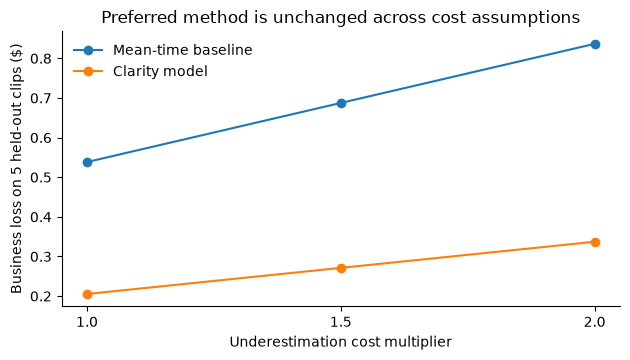


Decision rule: use the clarity-model prediction plus a 2.1-second
buffer (the 60% predictive quantile under the residual-normal approximation).


,Clarity,clarity_score,model_point_sec,planning_time_sec
0,clear,1,57.1,59.1
1,moderately unclear,2,73.7,75.8
2,very unclear,3,90.4,92.4


Worst held-out model underestimation: 9.3 s
Weighted cost of that miss under the base assumptions: $0.116
Observed value of model vs baseline under base assumptions: $0.083/clip
If this held-out performance generalized to 1,000 similar clips: about $83 less estimation loss.


In [8]:
# Part 3: business decision — convert timing error into labor-cost error.
# These are SCENARIO ASSUMPTIONS for the decision analysis, not measured customer prices.
HOURLY_RATE = 30.0               # dollars per reviewer-hour
UNDER_MULTIPLIER = 1.5           # underestimating work is assumed 1.5x as costly
OVER_MULTIPLIER = 1.0

actual_sec = test.review_time_sec_measured.to_numpy(dtype=float)
baseline_sec = np.asarray(test_pred_baseline, dtype=float)
model_sec = test_pred_model.to_numpy(dtype=float)

def decision_loss(actual, predicted, hourly_rate=HOURLY_RATE,
                  under_multiplier=UNDER_MULTIPLIER,
                  over_multiplier=OVER_MULTIPLIER):
    """Asymmetric absolute labor-cost loss for one or many clips."""
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    error_sec = actual - predicted  # positive means we underestimated the work
    multiplier = np.where(error_sec > 0, under_multiplier, over_multiplier)
    return np.abs(error_sec) / 3600 * hourly_rate * multiplier

# Approximate 90% prediction intervals for NEW clips under the fitted linear model.
# Includes residual spread and uncertainty from estimating the line.
n_train = len(train)
xbar = train.clarity_score.mean()
Sxx = ((train.clarity_score - xbar) ** 2).sum()
df_pred = n_train - 2
tcrit90 = stats.t.ppf(0.95, df_pred)
pred_se = resid_sd * np.sqrt(
    1 + 1 / n_train + (test.clarity_score.to_numpy() - xbar) ** 2 / Sxx
)
pred_lo90 = model_sec - tcrit90 * pred_se
pred_hi90 = model_sec + tcrit90 * pred_se
coverage90 = np.mean((actual_sec >= pred_lo90) & (actual_sec <= pred_hi90))

business_table = test[["Clip ID", "Clarity", "review_time_sec_measured"]].copy()
business_table["baseline_pred_sec"] = baseline_sec
business_table["model_pred_sec"] = model_sec
business_table["model_90_lo_sec"] = pred_lo90
business_table["model_90_hi_sec"] = pred_hi90
business_table["actual_labor_cost_$"] = actual_sec / 3600 * HOURLY_RATE
business_table["baseline_est_cost_$"] = baseline_sec / 3600 * HOURLY_RATE
business_table["model_est_cost_$"] = model_sec / 3600 * HOURLY_RATE
business_table["baseline_decision_loss_$"] = decision_loss(actual_sec, baseline_sec)
business_table["model_decision_loss_$"] = decision_loss(actual_sec, model_sec)

baseline_business_loss = business_table["baseline_decision_loss_$"].sum()
model_business_loss = business_table["model_decision_loss_$"].sum()
loss_reduction = baseline_business_loss - model_business_loss
loss_reduction_pct = loss_reduction / baseline_business_loss

print("Business assumptions:")
print(f"  reviewer labor rate = ${HOURLY_RATE:.0f}/hour")
print(f"  underestimation cost = {UNDER_MULTIPLIER:.1f}x ordinary labor cost")
print(f"  overestimation cost  = {OVER_MULTIPLIER:.1f}x ordinary labor cost")
print()
print(f"Business loss, baseline, 5 held-out clips: ${baseline_business_loss:.3f}")
print(f"Business loss, model,    5 held-out clips: ${model_business_loss:.3f}")
print(f"Reduction: ${loss_reduction:.3f} total = ${loss_reduction/len(test):.3f}/clip ({loss_reduction_pct:.1%})")
print(f"90% predictive-interval coverage on held-out clips: {coverage90:.0%} ({int(coverage90*len(test))}/{len(test)})")
print()
display(business_table.round(3))

# Sensitivity: does the preferred method change when labor rates or the
# underestimation penalty change?
sensitivity_rows = []
for rate in [20.0, 30.0, 45.0]:
    for under_mult in [1.0, 1.5, 2.0]:
        loss_b = decision_loss(actual_sec, baseline_sec, rate, under_mult, 1.0).sum()
        loss_m = decision_loss(actual_sec, model_sec, rate, under_mult, 1.0).sum()
        sensitivity_rows.append({
            "hourly_rate_$": rate,
            "underestimate_multiplier": under_mult,
            "baseline_loss_$": loss_b,
            "model_loss_$": loss_m,
            "preferred": "clarity model" if loss_m < loss_b else "baseline",
        })
sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity.round(3))

# Save the sensitivity figure used by the presentation.
sens30 = sensitivity[sensitivity["hourly_rate_$"] == 30].copy()
fig, ax = plt.subplots(figsize=(6.4, 3.7))
ax.plot(sens30["underestimate_multiplier"], sens30["baseline_loss_$"],
        marker="o", label="Mean-time baseline")
ax.plot(sens30["underestimate_multiplier"], sens30["model_loss_$"],
        marker="o", label="Clarity model")
ax.set_xlabel("Underestimation cost multiplier")
ax.set_ylabel("Business loss on 5 held-out clips ($)")
ax.set_title("Preferred method is unchanged across cost assumptions")
ax.set_xticks([1.0, 1.5, 2.0])
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("fig/business_loss_sensitivity.png", dpi=180)
plt.show()

# Explicit prediction -> action rule.
# For asymmetric absolute loss, the optimal quantile is
# c_under / (c_under + c_over). With 1.5x vs 1.0x, this is the 60th percentile.
planning_quantile = UNDER_MULTIPLIER / (UNDER_MULTIPLIER + OVER_MULTIPLIER)
planning_buffer_sec = stats.norm.ppf(planning_quantile) * resid_sd

clarity_plan = pd.DataFrame({
    "Clarity": ["clear", "moderately unclear", "very unclear"],
    "clarity_score": [1, 2, 3],
})
clarity_plan["model_point_sec"] = intercept + slope * clarity_plan["clarity_score"]
clarity_plan["planning_time_sec"] = clarity_plan["model_point_sec"] + planning_buffer_sec

print()
print(f"Decision rule: use the clarity-model prediction plus a {planning_buffer_sec:.1f}-second")
print(f"buffer (the {planning_quantile:.0%} predictive quantile under the residual-normal approximation).")
display(clarity_plan.round(1))

worst_under_sec = np.maximum(actual_sec - model_sec, 0).max()
worst_under_cost = worst_under_sec / 3600 * HOURLY_RATE * UNDER_MULTIPLIER
value_per_clip = loss_reduction / len(test)
value_per_1000 = value_per_clip * 1000

print(f"Worst held-out model underestimation: {worst_under_sec:.1f} s")
print(f"Weighted cost of that miss under the base assumptions: ${worst_under_cost:.3f}")
print(f"Observed value of model vs baseline under base assumptions: ${value_per_clip:.3f}/clip")
print(f"If this held-out performance generalized to 1,000 similar clips: about ${value_per_1000:.0f} less estimation loss.")


### Modeling limits

- Clarity was rated after timing and after preliminary AI-assisted ratings were seen, so it may not be independent evidence.
- There are only 20 clips, with 15 training and 5 held out; only two clips are `very unclear` in the full dataset.
- One reviewer performed all timed reviews, so reviewer-to-reviewer variation is unknown.
- All clips came from one evening and similar retail parking-lot scenes, so daylight, weather, other scene types, and full-video workflows are outside the evidence.
- The held-out result supports a comparison on this test set; it does not establish broad production performance.


### Part 3 business interpretation

**Customer and action.** The potential customer is a small annotation or imagery-review business that needs to quote and schedule batches of similar clips. Under the base scenario we assume reviewer labor costs **$30/hour**, an underestimated hour costs **1.5 times** as much as an overestimated hour because it can create rush/overtime pressure, and an overestimated hour costs the ordinary labor rate. These are scenario assumptions, not measured market prices.

**Loss.** For a clip with actual review time \(y\) seconds and estimate \(\hat y\),

\[
L(y,\hat y)=\frac{|y-\hat y|}{3600}\times \$30\times
\begin{cases}
1.5,& y>\hat y\quad\text{(underestimate)}\\
1.0,& y\le\hat y\quad\text{(overestimate)}.
\end{cases}
\]

At these assumptions the five held-out clips produce about **$0.688** of total loss with the mean-time baseline and **$0.271** with the clarity model, about a **61% reduction**. The model remains preferred in the sensitivity table for hourly rates of $20, $30, and $45 and underestimation multipliers of 1.0, 1.5, and 2.0.

**Decision rule.** Use the clarity model for **clip-level staffing and scheduling** on footage similar to this sample. Because underestimation is assumed to be more expensive, do not schedule exactly to the mean prediction: use the model prediction plus the 60th-percentile residual buffer (about **2.05 seconds per clip** under the fitted residual distribution). This gives planning times of about **59 s for clear**, **76 s for moderately unclear**, and **92 s for very unclear** clips.

**Important boundary.** On these five held-out clips, the baseline and model both predict almost the same total batch time (about 352 s versus 359 s actual). The evidence therefore supports the clarity model for *per-clip allocation and scheduling*, not a claim that it already improves the total quote for every batch.

**Risk.** The worst model underestimation in the held-out set is about **9.3 seconds**. Under the base cost assumptions, that single miss corresponds to about **$0.12** of weighted decision loss. All five held-out outcomes fall inside the model's approximate 90% prediction intervals, but \(n=5\) is far too small to treat 5/5 coverage as strong calibration evidence.

**Value of being less wrong.** The observed reduction in the chosen business loss is about **$0.083 per clip**. If, and only if, the same held-out advantage generalized to 1,000 similar clips, that would correspond to about **$83 less estimation loss**. This is a scenario extrapolation, not a demonstrated saving.

The main reasons not to generalize yet are the 20-clip sample, one reviewer, one evening/scene type, only two very-unclear clips, and especially the fact that clarity was rated after timing rather than blindly before timing. A blind re-rating and a larger multi-reviewer dataset are the first additional data worth collecting.
